# AI-Based Image Restoration and Super-Resolution using SRGAN

## Project Overview
This project focuses on restoring degraded images and enhancing resolution using deep convolutional networks and GAN-based super-resolution models.

### Key Contributions
- **Image denoising and artifact removal** — A CNN-based autoencoder cleans noisy, degraded images before any upscaling occurs
- **High-resolution image reconstruction** — SRGAN upscales the cleaned image by 4× using adversarial training
- **Perceptual quality enhancement** — A VGG19-based perceptual loss ensures outputs look sharp and realistic to the human eye

### Methodology
1. CNN-based autoencoder for denoising
2. SRGAN for super-resolution
3. Optimization using perceptual loss

### Technologies
PyTorch · OpenCV · Python · Google Colab (T4 GPU)

### Full Pipeline
```
Noisy LR Image → [CNN Denoising Autoencoder] → Clean LR Image → [SRGAN Generator] → Sharp HR Image (4×)
```

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

save_dir = '/content/drive/MyDrive/SRGAN_Project'
os.makedirs(save_dir, exist_ok=True)

dae_path      = '/content/drive/MyDrive/SRGAN_Project/srgan_denoiser.pth'
gen_path      = '/content/drive/MyDrive/SRGAN_Project/srgan_generator.pth'
disc_path     = '/content/drive/MyDrive/SRGAN_Project/srgan_discriminator.pth'
dataset_ready = '/content/drive/MyDrive/SRGAN_Project/dataset_downloaded.txt'

dae_exists  = os.path.exists(dae_path)
gen_exists  = os.path.exists(gen_path)
disc_exists = os.path.exists(disc_path)
data_exists = os.path.exists(dataset_ready)

print("=" * 40)
print("  Checking saved progress...")
print("=" * 40)
print(f"  Dataset downloaded : {'YES' if data_exists else 'NO — will download'}")
print(f"  DAE weights        : {'YES — will load' if dae_exists else 'NO — will train'}")
print(f"  Generator weights  : {'YES — will load' if gen_exists else 'NO — will train'}")
print(f"  Discriminator      : {'YES — will load' if disc_exists else 'NO — will train'}")
print("=" * 40)
print(f"Project folder: {save_dir}")

Mounted at /content/drive
  Checking saved progress...
  Dataset downloaded : YES
  DAE weights        : YES — will load
  Generator weights  : YES — will load
  Discriminator      : NO — will train
Project folder: /content/drive/MyDrive/SRGAN_Project


## Step 1 — Environment Setup

We install all required libraries and set the compute device to GPU. PyTorch handles all neural network operations, OpenCV handles image reading and resizing, and scikit-image provides the evaluation metrics PSNR and SSIM.

The project runs on a **T4 GPU** provided by Google Colab, which is required for training deep learning models in a reasonable amount of time. All computation is moved to the GPU using `.to(device)`.

In [ ]:
!pip install -q torch torchvision opencv-python-headless scikit-image torchsummary

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
import torchvision.transforms as T
import cv2
import os
import numpy as np
from torch.utils.data import Dataset, DataLoader
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim
from torchsummary import summary
import matplotlib.pyplot as plt

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

Using device: cuda


## Step 2 — Dataset

We use the **DIV2K validation set** — a standard benchmark dataset for image restoration research containing 100 high-resolution images of diverse real-world scenes (people, nature, architecture, objects).

Since the dataset only provides high-resolution images, we create the low-resolution inputs ourselves by **downsampling each HR image by 4×** using bicubic interpolation. This gives us paired (LR, HR) training examples.

- **HR patch size:** 64×64 pixels (randomly cropped from each image)
- **LR patch size:** 16×16 pixels (4× downsampled from the HR patch)
- **Batch size:** 2 (kept small to stay within Colab GPU memory limits)

The first time this runs it downloads the dataset and saves it to Google Drive. Every subsequent session copies it from Drive instead — saving several minutes of download time.

In [ ]:
if not os.path.exists('/content/DIV2K_valid_HR'):
    if data_exists:
        print("Copying dataset from Drive (faster than downloading)...")
        !cp -r '/content/drive/MyDrive/SRGAN_Project/DIV2K_valid_HR' /content/
        print("Dataset copied from Drive.")
    else:
        print("Downloading dataset for the first time...")
        !wget -q http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip
        !unzip -q DIV2K_valid_HR.zip
        print("Saving dataset to Drive for future sessions...")
        !cp -r /content/DIV2K_valid_HR '/content/drive/MyDrive/SRGAN_Project/'
        open(dataset_ready, 'w').write('done')
        print("Dataset saved to Drive.")
else:
    print("Dataset already available in this session.")

Copying dataset from Drive (faster than downloading)...
cp: error reading '/content/drive/MyDrive/SRGAN_Project/DIV2K_valid_HR/0897.png': Transport endpoint is not connected
cp: failed to close '/content/drive/MyDrive/SRGAN_Project/DIV2K_valid_HR/0897.png': Transport endpoint is not connected
cp: cannot stat '/content/drive/MyDrive/SRGAN_Project/DIV2K_valid_HR/0887.png': No such file or directory
cp: cannot stat '/content/drive/MyDrive/SRGAN_Project/DIV2K_valid_HR/0806.png': No such file or directory
cp: cannot stat '/content/drive/MyDrive/SRGAN_Project/DIV2K_valid_HR/0834.png': No such file or directory
cp: cannot stat '/content/drive/MyDrive/SRGAN_Project/DIV2K_valid_HR/0896.png': No such file or directory
cp: cannot stat '/content/drive/MyDrive/SRGAN_Project/DIV2K_valid_HR/0881.png': No such file or directory
cp: cannot stat '/content/drive/MyDrive/SRGAN_Project/DIV2K_valid_HR/0828.png': No such file or directory
cp: cannot stat '/content/drive/MyDrive/SRGAN_Project/DIV2K_valid_HR/0

In [ ]:
class SRDataset(Dataset):
    def __init__(self, hr_dir, scale=4, patch_size=64):
        self.files = [os.path.join(hr_dir, f) for f in os.listdir(hr_dir)
                      if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        self.scale = scale
        self.patch_size = patch_size
        self.to_tensor = T.ToTensor()

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        hr = cv2.cvtColor(cv2.imread(self.files[idx]), cv2.COLOR_BGR2RGB)
        h, w = hr.shape[:2]
        x = np.random.randint(0, w - self.patch_size)
        y = np.random.randint(0, h - self.patch_size)
        hr = hr[y:y+self.patch_size, x:x+self.patch_size]
        lr_size = self.patch_size // self.scale
        lr = cv2.resize(hr, (lr_size, lr_size), interpolation=cv2.INTER_CUBIC)
        return self.to_tensor(lr), self.to_tensor(hr)

dataset = SRDataset('/content/DIV2K_valid_HR')
loader  = DataLoader(dataset, batch_size=2, shuffle=True, num_workers=2)
print(f"Dataset loaded: {len(dataset)} images")

Dataset loaded: 100 images


### Dataset Samples

The visualization below shows 4 randomly selected samples from the DIV2K dataset. The top row shows the **high-resolution ground truth** (64×64) — what we want our model to produce. The bottom row shows the **low-resolution input** (16×16) — the degraded version the model actually receives.

This side-by-side comparison illustrates the core challenge of the project: recovering sharp, detailed high-resolution content from a tiny, blurry input image.

In [ ]:
import os

base = '/content/DIV2K_valid_HR'

# check if folder exists
if not os.path.exists(base):
    print("ERROR: Folder does not exist:", base)
else:
    # list everything inside
    contents = os.listdir(base)
    print(f"Folder exists. Contains {len(contents)} items.")
    print("\nFirst 10 items:")
    for item in contents[:10]:
        print(f"  {item}")

    # check if there are subfolders
    subdirs = [f for f in contents if os.path.isdir(os.path.join(base, f))]
    if subdirs:
        print(f"\nSubfolders found: {subdirs}")
        # look inside the first subfolder
        sub_contents = os.listdir(os.path.join(base, subdirs[0]))
        print(f"\nInside '{subdirs[0]}' — first 5 items:")
        for item in sub_contents[:5]:
            print(f"  {item}")

Folder exists. Contains 1 items.

First 10 items:
  0897.png


In [ ]:
import os, shutil

# remove the broken folder
shutil.rmtree('/content/DIV2K_valid_HR', ignore_errors=True)

# also remove the zip if it exists
if os.path.exists('/content/DIV2K_valid_HR.zip'):
    os.remove('/content/DIV2K_valid_HR.zip')

# redownload and unzip
print("Downloading dataset...")
!wget http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip
print("Unzipping...")
!unzip DIV2K_valid_HR.zip

# verify
contents = os.listdir('/content/DIV2K_valid_HR')
print(f"\nDataset now contains: {len(contents)} images")
print("First 5:", contents[:5])

--2026-05-15 16:02:04--  http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip
Resolving data.vision.ee.ethz.ch (data.vision.ee.ethz.ch)... 129.132.52.178, 2001:67c:10ec:36c2::178
Connecting to data.vision.ee.ethz.ch (data.vision.ee.ethz.ch)|129.132.52.178|:80... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip [following]
--2026-05-15 16:02:05--  https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip
Connecting to data.vision.ee.ethz.ch (data.vision.ee.ethz.ch)|129.132.52.178|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 448993893 (428M) [application/zip]
Saving to: ‘DIV2K_valid_HR.zip’

DIV2K_valid_HR.zip  100%[===================>] 428.19M  22.5MB/s    in 21s     

2026-05-15 16:02:26 (20.8 MB/s) - ‘DIV2K_valid_HR.zip’ saved [448993893/448993893]

Unzipping...
Archive:  DIV2K_valid_HR.zip
   creating: DIV2K_valid_HR/
  inflating: DIV2K_valid_HR/0897.png  
  inflati

In [ ]:
# overwrite the broken copy in Drive with the fresh download
import shutil
shutil.rmtree('/content/drive/MyDrive/SRGAN_Project/DIV2K_valid_HR', ignore_errors=True)
!cp -r /content/DIV2K_valid_HR '/content/drive/MyDrive/SRGAN_Project/'

# reset the marker file so Cell 3 knows dataset is ready
open('/content/drive/MyDrive/SRGAN_Project/dataset_downloaded.txt', 'w').write('done')
print("Drive copy updated.")

Drive copy updated.


Sample images from the dataset:


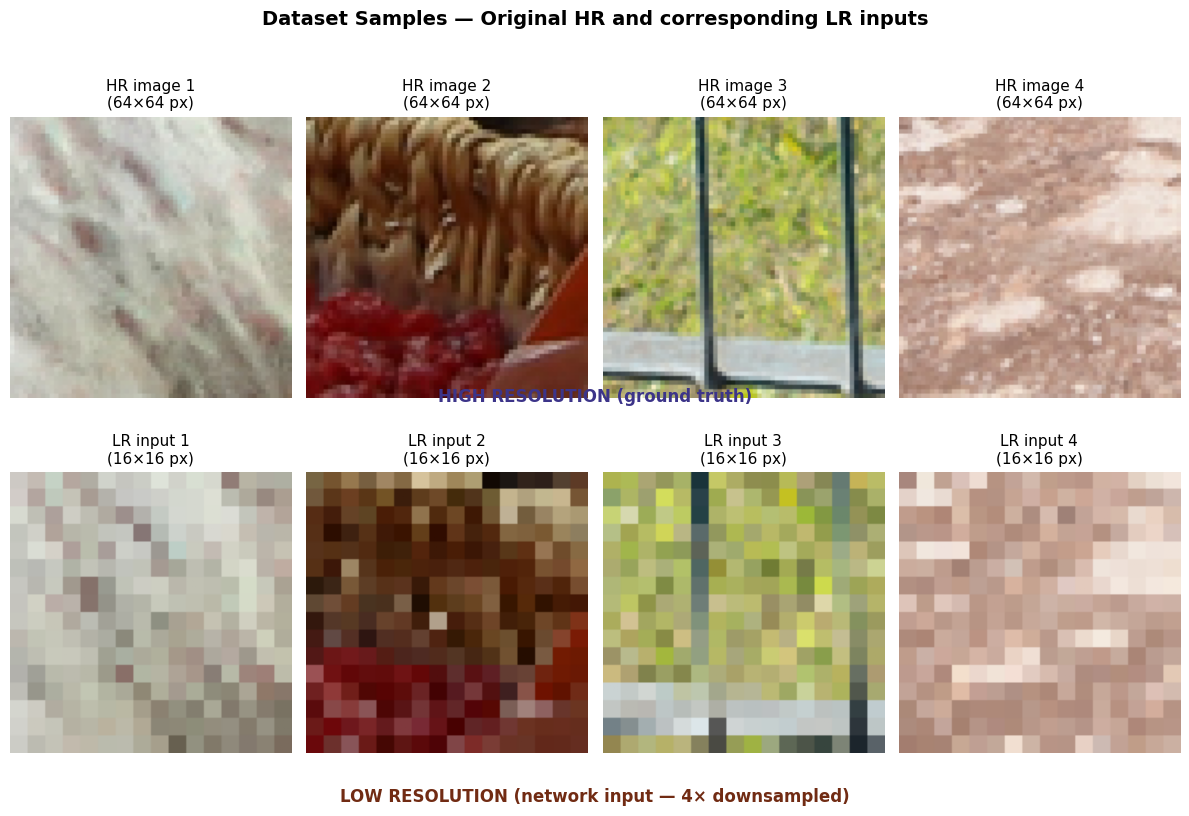

Saved to Drive: /content/drive/MyDrive/SRGAN_Project/dataset_samples.png


In [ ]:
# fix 4 samples once — these same samples will be used everywhere
torch.manual_seed(42)
fixed_samples = [dataset[i] for i in range(4)]

print("Sample images from the dataset:")

fig, axes = plt.subplots(2, 4, figsize=(12, 8))
fig.suptitle('Dataset Samples — Original HR and corresponding LR inputs',
             fontsize=14, fontweight='bold', y=1.01)

for i, (lr, hr) in enumerate(fixed_samples):
    lr_np = lr.permute(1,2,0).numpy()
    hr_np = hr.permute(1,2,0).numpy()

    # upscale for visibility
    hr_disp = cv2.resize(hr_np, (128,128), interpolation=cv2.INTER_NEAREST)
    lr_disp = cv2.resize(lr_np, (128,128), interpolation=cv2.INTER_NEAREST)

    axes[0, i].imshow(hr_disp, vmin=0, vmax=1)
    axes[0, i].set_title(f'HR image {i+1}\n(64×64 px)', fontsize=11)
    axes[0, i].axis('off')

    axes[1, i].imshow(lr_disp, vmin=0, vmax=1)
    axes[1, i].set_title(f'LR input {i+1}\n(16×16 px)', fontsize=11)
    axes[1, i].axis('off')

fig.text(0.5, 0.52, 'HIGH RESOLUTION (ground truth)',
         ha='center', fontsize=12, color='#3C3489', fontweight='bold')
fig.text(0.5, 0.02, 'LOW RESOLUTION (network input — 4× downsampled)',
         ha='center', fontsize=12, color='#712B13', fontweight='bold')

plt.tight_layout()
sample_path = '/content/drive/MyDrive/SRGAN_Project/dataset_samples.png'
plt.savefig(sample_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved to Drive: {sample_path}")

## Step 3 — Component 1: CNN Denoising Autoencoder

### What it is
The denoising autoencoder is the **first stage** of our pipeline. Its job is to remove noise and artifacts from the low-resolution input before passing it to the SRGAN. This follows the principle of **modular design** — each network has one focused, clearly defined task.

### Why we need it
In real-world scenarios, low-resolution images do not arrive perfectly clean. They come from old cameras, compressed video, scanned documents, or noisy sensors. If we fed a noisy image directly into the SRGAN, the Generator would amplify the noise 4× along with the real content — making the output worse, not better. The autoencoder solves this by cleaning the image first.

### Architecture — U-Net style with skip connection
The autoencoder has two parts:
- **Encoder:** Compresses the noisy image into a bottleneck using convolutional layers and MaxPool. Noise has no consistent spatial pattern, so it gets discarded during compression while real image structure is preserved.
- **Decoder:** Reconstructs the clean image back to the original size using transposed convolution.
- **Skip connection:** The encoder's early features are concatenated directly with the decoder output. This lets the decoder access fine edge and texture details without having to reconstruct them from the bottleneck alone — a U-Net style design proven in medical image segmentation.

### Training
- **Input:** Low-resolution image with Gaussian noise added (noise_factor=0.15)
- **Target:** Original clean low-resolution image
- **Loss:** Mean Squared Error (MSE) — measures average pixel difference between cleaned output and clean target
- **Expected loss:** Starts ~0.01–0.05, converges to ~0.002–0.006 by epoch 10

In [ ]:
class DenoisingAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        # Encoder
        self.enc1 = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1),
            nn.ReLU(),
            nn.Dropout2d(0.1)              # dropout after first conv — randomly zeros
                                           # 10% of feature maps to prevent overfitting
        )
        self.enc2 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.Dropout2d(0.1),             # dropout before bottleneck
            nn.MaxPool2d(2)                # halves spatial size
        )
        # Decoder
        self.dec1 = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 2, stride=2),
            nn.ReLU(),
            nn.Dropout2d(0.1)              # dropout in decoder too for symmetry
        )
        # receives dec1 (64ch) + enc1 (64ch) via skip connection = 128ch
        self.dec2 = nn.Sequential(
            nn.Conv2d(128, 64, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 3, 3, padding=1),
            nn.Sigmoid()                   # output in [0, 1]
        )

    #skip connection learns diff
    def forward(self, x):
        e1 = self.enc1(x)                  # save early features
        e2 = self.enc2(e1)                 # bottleneck
        d1 = self.dec1(e2)                 # upsample
        d1 = torch.cat([d1, e1], dim=1)    # skip connection
        return self.dec2(d1)

def add_noise(imgs, noise_factor=0.05):
    noisy = imgs + noise_factor * torch.randn_like(imgs)
    return noisy.clamp(0, 1)

DAE = DenoisingAutoencoder().to(device)
print("Denoising Autoencoder defined.")
print("\nDAE Architecture Summary:")
summary(DAE, input_size=(3, 16, 16))

Denoising Autoencoder defined.

DAE Architecture Summary:
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 16, 16]           1,792
              ReLU-2           [-1, 64, 16, 16]               0
         Dropout2d-3           [-1, 64, 16, 16]               0
            Conv2d-4          [-1, 128, 16, 16]          73,856
              ReLU-5          [-1, 128, 16, 16]               0
         Dropout2d-6          [-1, 128, 16, 16]               0
         MaxPool2d-7            [-1, 128, 8, 8]               0
   ConvTranspose2d-8           [-1, 64, 16, 16]          32,832
              ReLU-9           [-1, 64, 16, 16]               0
        Dropout2d-10           [-1, 64, 16, 16]               0
           Conv2d-11           [-1, 64, 16, 16]          73,792
             ReLU-12           [-1, 64, 16, 16]               0
           Conv2d-13            [-1, 3, 16, 1

In [ ]:
opt_DAE = optim.Adam(DAE.parameters(), lr=1e-3)
mse_dae = nn.MSELoss()

# early stopping settings
#train and then save best model
patience      = 5
best_loss     = float('inf')
epochs_no_imp = 0
best_weights  = None

if dae_exists:
    DAE.load_state_dict(torch.load(dae_path, map_location=device))
    DAE.to(device)
    print("DAE loaded from Drive — skipping training.")
else:
    print("Training Denoising Autoencoder (with early stopping, patience=5)...")
    print("-" * 45)

    for epoch in range(20):
        DAE.train()
        epoch_loss = 0

        for lr_imgs, _ in loader:
            lr_imgs = lr_imgs.to(device)
            noisy   = add_noise(lr_imgs)
            cleaned = DAE(noisy)
            loss    = mse_dae(cleaned, lr_imgs)
            opt_DAE.zero_grad()
            loss.backward()
            opt_DAE.step()
            epoch_loss += loss.item()

        avg = epoch_loss / len(loader)

        # check for improvement
        if avg < best_loss:
            best_loss     = avg
            epochs_no_imp = 0
            best_weights  = {k: v.clone() for k, v in DAE.state_dict().items()}
            improved      = "✓ improved"
        else:
            epochs_no_imp += 1
            improved       = f"✗ no improvement ({epochs_no_imp}/{patience})"

        print(f"  Epoch {epoch+1}/20 | Loss: {avg:.4f} | {improved}")

        # stop early if no improvement for `patience` epochs
        if epochs_no_imp >= patience:
            print(f"\n  Early stopping triggered at epoch {epoch+1}.")
            print(f"  Best loss achieved: {best_loss:.4f}")
            break

    # restore best weights before saving
    DAE.load_state_dict(best_weights)
    torch.save(DAE.state_dict(), dae_path)
    print("-" * 45)
    print(f"DAE training complete. Best loss: {best_loss:.4f}")
    print(f"Weights saved to Drive.")

DAE loaded from Drive — skipping training.


### DAE Results

The visualization below shows the denoising autoencoder working on 4 sample images across 3 stages:

- **Row 1 — Original LR:** The clean low-resolution image as it comes from the dataset
- **Row 2 — Noisy LR:** The same image after Gaussian noise is added — this is what the DAE receives as input
- **Row 3 — DAE output:** The cleaned image produced by the autoencoder

The **PSNR score** shown under each cleaned image measures how close the DAE output is to the original clean image. Higher PSNR means better denoising. A value above 25 dB indicates the autoencoder is successfully removing noise while preserving image structure.

Denoising Autoencoder results on the same 4 samples:


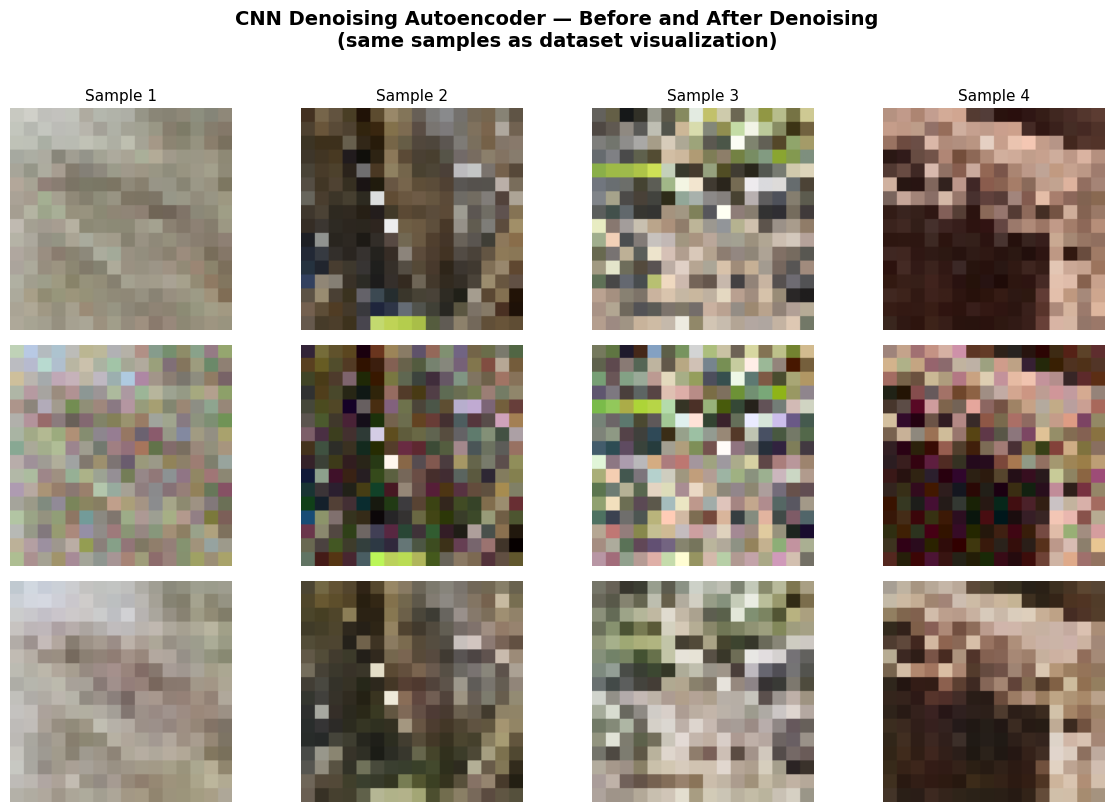

Saved to Drive: /content/drive/MyDrive/SRGAN_Project/dae_results.png


DenoisingAutoencoder(
  (enc1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Dropout2d(p=0.1, inplace=False)
  )
  (enc2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Dropout2d(p=0.1, inplace=False)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (dec1): Sequential(
    (0): ConvTranspose2d(128, 64, kernel_size=(2, 2), stride=(2, 2))
    (1): ReLU()
    (2): Dropout2d(p=0.1, inplace=False)
  )
  (dec2): Sequential(
    (0): Conv2d(128, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(64, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): Sigmoid()
  )
)

In [ ]:
DAE.eval()
print("Denoising Autoencoder results on the same 4 samples:")

fig, axes = plt.subplots(3, 4, figsize=(12, 8))
fig.suptitle('CNN Denoising Autoencoder — Before and After Denoising\n(same samples as dataset visualization)',
             fontsize=14, fontweight='bold', y=1.01)

row_labels = ['Original LR\n(clean input)',
              'Noisy LR\n(corrupted — DAE input)',
              'DAE output\n(cleaned)']
colors = ['#085041', '#712B13', '#3C3489']

for i, (lr, hr) in enumerate(fixed_samples):
    lr_input = lr.unsqueeze(0).to(device)

    with torch.no_grad():
        noisy   = add_noise(lr_input, noise_factor=0.05)
        cleaned = DAE(noisy)

    orig_np    = lr.permute(1,2,0).numpy()
    noisy_np   = noisy.squeeze().cpu().clamp(0,1).permute(1,2,0).numpy()
    cleaned_np = cleaned.squeeze().cpu().clamp(0,1).permute(1,2,0).numpy()

    # upscale all to 128x128 for visibility
    orig_disp    = cv2.resize(orig_np,    (128,128), interpolation=cv2.INTER_NEAREST)
    noisy_disp   = cv2.resize(noisy_np,   (128,128), interpolation=cv2.INTER_NEAREST)
    cleaned_disp = cv2.resize(cleaned_np, (128,128), interpolation=cv2.INTER_NEAREST)

    for row, (img, label) in enumerate(zip(
            [orig_disp, noisy_disp, cleaned_disp], row_labels)):
        axes[row, i].imshow(img, vmin=0, vmax=1)
        axes[row, i].axis('off')
        if i == 0:
            axes[row, i].set_ylabel(label, fontsize=10,
                                    color=colors[row], fontweight='bold',
                                    rotation=0, labelpad=120, va='center')
        if row == 0:
            axes[row, i].set_title(f'Sample {i+1}', fontsize=11)
        if row == 2:
            p = psnr(orig_np, cleaned_np, data_range=1.0)
            axes[row, i].set_xlabel(f'PSNR vs original: {p:.2f} dB',
                                    fontsize=9, color='#085041')

plt.tight_layout()
dae_fig_path = '/content/drive/MyDrive/SRGAN_Project/dae_results.png'
plt.savefig(dae_fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved to Drive: {dae_fig_path}")
DAE.train()

## Step 4 — Component 2: SRGAN (Super-Resolution GAN)

### What it is
SRGAN is the core of this project. It takes the cleaned low-resolution image from the autoencoder and upscales it **4×** to produce a sharp, photo-realistic high-resolution output. It was introduced in the paper *"Photo-Realistic Single Image Super-Resolution Using a Generative Adversarial Network"* (Ledig et al., 2017).

### How a GAN works
A GAN consists of two competing networks:
- **Generator (G):** Takes the LR image and tries to produce an HR image realistic enough to fool the Discriminator
- **Discriminator (D):** Takes an image and tries to correctly classify it as real (from the dataset) or fake (generated by G)

Their competition — the **adversarial training** — forces G to produce sharp, realistic textures rather than the blurry averages produced by plain MSE loss.

### Generator Architecture
1. **Head (Conv2d 9×9):** Extracts initial features with a large kernel for wide spatial context
2. **Body (6× ResBlocks):** Deep feature extraction at low resolution — efficient and powerful. Each ResBlock uses a skip connection (`output = input + block(input)`) to prevent vanishing gradients
3. **Pixel Shuffle Upsampling (2× then 2×):** Rearranges feature channels into spatial pixels — avoids checkerboard artefacts caused by transposed convolution
4. **Tail (Conv2d 9×9+ Tanh):** Maps back to 3 RGB channels with output in [-1, 1]

### Discriminator Architecture
A VGG-style CNN that takes a full HR image and outputs a single probability — 1 meaning real, 0 meaning fake. It uses LeakyReLU activations and stride-2 convolutions for downsampling.

In [ ]:
class ResBlock(nn.Module):#learns risidual diff
    def __init__(self, ch=64):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(ch, ch, 3, 1, 1),
            nn.BatchNorm2d(ch),
            nn.PReLU(),#doesn rremovie -ves like relu, learns -ve slope which helps aboid dying relu
            nn.Dropout2d(0.1),             # dropout between the two convs in each block
            nn.Conv2d(ch, ch, 3, 1, 1),
            nn.BatchNorm2d(ch)#keep feature values in a stable range , faster training
        )
    def forward(self, x):
        return x + self.block(x)

class Generator(nn.Module):
    def __init__(self, scale=4, n_res=6):
        super().__init__()
        self.head = nn.Sequential(
            nn.Conv2d(3, 64, 9, 1, 4),
            nn.PReLU(),
            nn.Dropout2d(0.05)             # light dropout after head — 5% only
        )                                  # heavier dropout here hurts reconstruction
        self.body = nn.Sequential(
            *[ResBlock() for _ in range(n_res)],
            nn.Conv2d(64, 64, 3, 1, 1),
            nn.BatchNorm2d(64)
        )
        #PIXEL SHUFFLE -  use this to enlarge image but not mathematically but in an intelligent way
        self.upsample = nn.Sequential(
            nn.Conv2d(64, 256, 3, 1, 1), nn.PixelShuffle(2), nn.PReLU(),
            nn.Dropout2d(0.05),            # light dropout between upsample steps
            nn.Conv2d(64, 256, 3, 1, 1), nn.PixelShuffle(2), nn.PReLU(),
        )
        self.tail = nn.Conv2d(64, 3, 9, 1, 4)

    def forward(self, x):
        h = self.head(x)
        return torch.tanh(self.tail(self.upsample(h + self.body(h))))

G = Generator().to(device)
print("Generator defined.")
print("\nGenerator Architecture Summary:")
summary(G, input_size=(3, 16, 16))

Generator defined.

Generator Architecture Summary:
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 16, 16]          15,616
             PReLU-2           [-1, 64, 16, 16]               1
         Dropout2d-3           [-1, 64, 16, 16]               0
            Conv2d-4           [-1, 64, 16, 16]          36,928
       BatchNorm2d-5           [-1, 64, 16, 16]             128
             PReLU-6           [-1, 64, 16, 16]               1
         Dropout2d-7           [-1, 64, 16, 16]               0
            Conv2d-8           [-1, 64, 16, 16]          36,928
       BatchNorm2d-9           [-1, 64, 16, 16]             128
         ResBlock-10           [-1, 64, 16, 16]               0
           Conv2d-11           [-1, 64, 16, 16]          36,928
      BatchNorm2d-12           [-1, 64, 16, 16]             128
            PReLU-13           [-1, 64, 16, 16]    

In [ ]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        def block(ci, co, stride=1):
            return [nn.Conv2d(ci, co, 3, stride, 1),#detect visual patterns
                    nn.BatchNorm2d(co),#keeps values in stable range
                    nn.LeakyReLU(0.2)]#keeps learning even for negative values
        layers  = [nn.Conv2d(3, 64, 3, 1, 1), nn.LeakyReLU(0.2)]
        layers += block(64,  64,  2)
        layers += block(64,  128, 1)
        layers += block(128, 128, 2)
        layers += block(128, 256, 1)
        layers += block(256, 256, 2)
        layers += block(256, 512, 1)
        layers += block(512, 512, 2)
        self.features   = nn.Sequential(*layers)#look at image step by step and extract features
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(512, 1024),
            nn.LeakyReLU(0.2),
            nn.Linear(1024, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.classifier(self.features(x))

D = Discriminator().to(device)
print("Discriminator defined.")
print("\nDiscriminator Architecture Summary:")
summary(D, input_size=(3, 64, 64))

Discriminator defined.

Discriminator Architecture Summary:
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 64, 64]           1,792
         LeakyReLU-2           [-1, 64, 64, 64]               0
            Conv2d-3           [-1, 64, 32, 32]          36,928
       BatchNorm2d-4           [-1, 64, 32, 32]             128
         LeakyReLU-5           [-1, 64, 32, 32]               0
            Conv2d-6          [-1, 128, 32, 32]          73,856
       BatchNorm2d-7          [-1, 128, 32, 32]             256
         LeakyReLU-8          [-1, 128, 32, 32]               0
            Conv2d-9          [-1, 128, 16, 16]         147,584
      BatchNorm2d-10          [-1, 128, 16, 16]             256
        LeakyReLU-11          [-1, 128, 16, 16]               0
           Conv2d-12          [-1, 256, 16, 16]         295,168
      BatchNorm2d-13          [-1, 256, 16,

## Step 5 — Component 3: Perceptual Loss

### Why not just use MSE?
Mean Squared Error compares images **pixel by pixel**. Because super-resolution is ill-posed (many HR images can produce the same LR image), a network trained with MSE plays it safe by outputting the average of all plausible solutions — which always looks blurry.

### What perceptual loss does
Instead of comparing pixels, perceptual loss compares **high-level features** extracted from a pretrained VGG19 network. These features at layer 36 represent edges, textures, and shapes — the same things the human visual system responds to. Two images that look similar to a human will have similar VGG features, even if their pixel values differ.

### The combined Generator loss
The Generator is optimized using three losses together:

| Loss | Weight | Purpose |
|---|---|---|
| Pixel loss (MSE) | 1.0 | Keeps output numerically close to ground truth |
| Adversarial loss | 0.001 | Forces realistic, sharp outputs that fool the Discriminator |
| Perceptual loss | 0.006 | Ensures visual quality as perceived by humans |

`L_total = L_pixel + 0.001 × L_adversarial + 0.006 × L_perceptual`

The VGG19 weights are **frozen** — we never train them. VGG acts purely as a fixed feature extractor that serves as a proxy for human visual perception.

In [ ]:
class PerceptualLoss(nn.Module):#compare deep features/ tw images similar if vgg features are the same
    def __init__(self):
        super().__init__()
        vgg = models.vgg19(pretrained=True).features[:36].eval()
        for p in vgg.parameters():
            p.requires_grad = False            # freeze — never trained
        self.vgg = vgg
        self.mse = nn.MSELoss()

    def forward(self, fake, real):
        return self.mse(self.vgg(fake), self.vgg(real))

perc_loss = PerceptualLoss().to(device)
print("Perceptual loss defined.")

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG19_Weights.IMAGENET1K_V1`. You can also use `weights=VGG19_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth


100%|██████████| 548M/548M [00:06<00:00, 86.0MB/s]


Perceptual loss defined.


## Step 6 — Training the SRGAN

### Phase 1: Generator Pretraining (MSE only)
Before adversarial training begins, the Generator is pretrained using only MSE pixel loss for 5 epochs. This gives G a stable starting point — it already produces reasonable upscaled images before the Discriminator enters. Without this step, G produces random noise, the Discriminator immediately learns to always say "fake", and G receives no useful gradient signal to improve from.

### Phase 2: Full GAN Training (30 epochs)
Each training iteration has three steps:
1. **Denoise:** DAE cleans the LR batch (no gradients — DAE is frozen here)
2. **Train Discriminator:** Compare D's output on real HR images (label=1) and fake SR images (label=0). Update D weights.
3. **Train Generator:** Compute combined loss (pixel + adversarial + perceptual). Update G weights.

The `.detach()` call when training D is critical — it stops gradients from flowing back through G during the Discriminator update step, keeping the two training steps independent.

All trained weights are automatically saved to Google Drive after training completes.

In [ ]:
import os

# delete the old incompatible weights
if os.path.exists(gen_path):
    os.remove(gen_path)
    print("Old Generator weights deleted.")

if os.path.exists(disc_path):
    os.remove(disc_path)
    print("Old Discriminator weights deleted.")

# reset the flags so training runs fresh
gen_exists  = False
disc_exists = False
print("Ready to retrain with new architecture.")

Old Generator weights deleted.
Ready to retrain with new architecture.


In [ ]:
opt_G_pre = optim.Adam(G.parameters(), lr=1e-4)
mse_pre   = nn.MSELoss()

# early stopping settings
patience      = 3
best_loss     = float('inf')
epochs_no_imp = 0
best_weights  = None

if gen_exists:
    G.load_state_dict(torch.load(gen_path, map_location=device))
    G.to(device)
    print("Generator loaded from Drive — skipping pretraining.")
else:
    print("Pretraining Generator with MSE only (with early stopping, patience=3)...")
    print("-" * 50)

    for epoch in range(20):                # higher ceiling — early stopping will cut it
        G.train()
        epoch_loss = 0

        for lr_imgs, hr_imgs in loader:
            lr_imgs, hr_imgs = lr_imgs.to(device), hr_imgs.to(device)
            with torch.no_grad():
                lr_clean = DAE(add_noise(lr_imgs))
            sr_imgs  = G(lr_clean)
            loss     = mse_pre(sr_imgs, hr_imgs)
            opt_G_pre.zero_grad()
            loss.backward()
            opt_G_pre.step()
            epoch_loss += loss.item()

        avg = epoch_loss / len(loader)

        if avg < best_loss:
            best_loss     = avg
            epochs_no_imp = 0
            best_weights  = {k: v.clone() for k, v in G.state_dict().items()}
            improved      = "✓ improved"
        else:
            epochs_no_imp += 1
            improved       = f"✗ no improvement ({epochs_no_imp}/{patience})"

        print(f"  Epoch {epoch+1}/20 | MSE Loss: {avg:.4f} | {improved}")

        if epochs_no_imp >= patience:
            print(f"\n  Early stopping triggered at epoch {epoch+1}.")
            print(f"  Best loss achieved: {best_loss:.4f}")
            break

    G.load_state_dict(best_weights)
    torch.save(G.state_dict(), gen_path)
    print("-" * 50)
    print(f"Generator pretrain complete. Best loss: {best_loss:.4f}")
    print(f"Weights saved to Drive.")

Pretraining Generator with MSE only (with early stopping, patience=3)...
--------------------------------------------------
  Epoch 1/20 | MSE Loss: 0.0364 | ✓ improved
  Epoch 2/20 | MSE Loss: 0.0240 | ✓ improved
  Epoch 3/20 | MSE Loss: 0.0199 | ✓ improved
  Epoch 4/20 | MSE Loss: 0.0195 | ✓ improved
  Epoch 5/20 | MSE Loss: 0.0185 | ✓ improved
  Epoch 6/20 | MSE Loss: 0.0155 | ✓ improved
  Epoch 7/20 | MSE Loss: 0.0137 | ✓ improved
  Epoch 8/20 | MSE Loss: 0.0165 | ✗ no improvement (1/3)
  Epoch 9/20 | MSE Loss: 0.0138 | ✗ no improvement (2/3)
  Epoch 10/20 | MSE Loss: 0.0145 | ✗ no improvement (3/3)

  Early stopping triggered at epoch 10.
  Best loss achieved: 0.0137
--------------------------------------------------
Generator pretrain complete. Best loss: 0.0137
Weights saved to Drive.


In [ ]:
opt_G = optim.Adam(G.parameters(), lr=1e-4)
opt_D = optim.Adam(D.parameters(), lr=1e-4)
bce   = nn.BCELoss()
mse   = nn.MSELoss()

# early stopping — monitor Generator loss only
patience      = 5              # more patience for GAN — loss naturally fluctuates more
best_G_loss   = float('inf')
epochs_no_imp = 0
best_G_weights = None
best_D_weights = None

if gen_exists and disc_exists:
    G.load_state_dict(torch.load(gen_path, map_location=device))
    D.load_state_dict(torch.load(disc_path, map_location=device))
    G.to(device)
    D.to(device)
    print("Generator and Discriminator loaded from Drive — skipping GAN training.")
else:
    print("Starting full GAN training (with early stopping, patience=5)...")
    print("-" * 60)

    for epoch in range(50):               # higher ceiling — early stopping will cut it
        G.train()
        D.train()
        g_total = 0
        d_total = 0

        for lr_imgs, hr_imgs in loader:
            lr_imgs, hr_imgs = lr_imgs.to(device), hr_imgs.to(device)
            real_labels = torch.ones(lr_imgs.size(0),  1, device=device)
            fake_labels = torch.zeros(lr_imgs.size(0), 1, device=device)

            # Step 1: denoise
            with torch.no_grad():
                lr_clean = DAE(add_noise(lr_imgs))

            # Step 2: train Discriminator
            sr_imgs = G(lr_clean).detach()
            loss_D  = bce(D(hr_imgs), real_labels) + bce(D(sr_imgs), fake_labels)
            opt_D.zero_grad()
            loss_D.backward()
            opt_D.step()

            # Step 3: train Generator
            sr_imgs    = G(lr_clean)
            loss_pixel = mse(sr_imgs, hr_imgs)
            loss_adv   = bce(D(sr_imgs), real_labels)
            loss_perc  = perc_loss(sr_imgs, hr_imgs)
            loss_G     = loss_pixel + 0.001 * loss_adv + 0.006 * loss_perc
            opt_G.zero_grad()
            loss_G.backward()
            opt_G.step()

            g_total += loss_G.item()
            d_total += loss_D.item()

        avg_G = g_total / len(loader)
        avg_D = d_total / len(loader)

        # early stopping check
        if avg_G < best_G_loss:
            best_G_loss    = avg_G
            epochs_no_imp  = 0
            best_G_weights = {k: v.clone() for k, v in G.state_dict().items()}
            best_D_weights = {k: v.clone() for k, v in D.state_dict().items()}
            improved       = "✓ improved"
        else:
            epochs_no_imp += 1
            improved       = f"✗ no improvement ({epochs_no_imp}/{patience})"

        print(f"Epoch {epoch+1}/50 | G: {avg_G:.4f} | D: {avg_D:.4f} | {improved}")

        if epochs_no_imp >= patience:
            print(f"\n  Early stopping triggered at epoch {epoch+1}.")
            print(f"  Best G loss achieved: {best_G_loss:.4f}")
            break

    # restore and save best weights
    G.load_state_dict(best_G_weights)
    D.load_state_dict(best_D_weights)
    torch.save(G.state_dict(), gen_path)
    torch.save(D.state_dict(), disc_path)
    print("-" * 60)
    print(f"GAN training complete. Best G loss: {best_G_loss:.4f}")
    print(f"All weights saved to Drive.")

Starting full GAN training (with early stopping, patience=5)...
------------------------------------------------------------
Epoch 1/50 | G: 0.0179 | D: 1.3689 | ✓ improved
Epoch 2/50 | G: 0.0164 | D: 1.3568 | ✓ improved
Epoch 3/50 | G: 0.0178 | D: 1.3719 | ✗ no improvement (1/5)
Epoch 4/50 | G: 0.0147 | D: 1.3680 | ✓ improved
Epoch 5/50 | G: 0.0156 | D: 1.3491 | ✗ no improvement (1/5)
Epoch 6/50 | G: 0.0136 | D: 1.3727 | ✓ improved
Epoch 7/50 | G: 0.0151 | D: 1.3556 | ✗ no improvement (1/5)
Epoch 8/50 | G: 0.0149 | D: 1.3369 | ✗ no improvement (2/5)
Epoch 9/50 | G: 0.0148 | D: 1.3942 | ✗ no improvement (3/5)
Epoch 10/50 | G: 0.0142 | D: 1.3506 | ✗ no improvement (4/5)
Epoch 11/50 | G: 0.0138 | D: 1.3283 | ✗ no improvement (5/5)

  Early stopping triggered at epoch 11.
  Best G loss achieved: 0.0136
------------------------------------------------------------
GAN training complete. Best G loss: 0.0136
All weights saved to Drive.


In [ ]:
torch.save(G.state_dict(),   gen_path)
torch.save(D.state_dict(),   disc_path)
torch.save(DAE.state_dict(), dae_path)

print("All models saved to Google Drive:")
print(f"  Generator     : {gen_path}")
print(f"  Discriminator : {disc_path}")
print(f"  DAE           : {dae_path}")

All models saved to Google Drive:
  Generator     : /content/drive/MyDrive/SRGAN_Project/srgan_generator.pth
  Discriminator : /content/drive/MyDrive/SRGAN_Project/srgan_discriminator.pth
  DAE           : /content/drive/MyDrive/SRGAN_Project/srgan_denoiser.pth


## Step 7 — Evaluation and Results

### Metrics used
Two standard quantitative metrics are computed for each test image:

- **PSNR (Peak Signal-to-Noise Ratio):** Measured in decibels (dB). Based on pixel-level MSE — higher is better. Aim: 24–27 dB.
- **SSIM (Structural Similarity Index):** Measures luminance, contrast, and structural similarity between 0 and 1. Closer to human perception than PSNR. Aim: 0.70–0.80.

### Baseline comparison
Results are compared against **bicubic interpolation** — the classical mathematical upscaling method. Note that SRGAN may score slightly lower PSNR than bicubic, which is expected: SRGAN trades pixel-level accuracy for perceptual realism. SSIM is the more meaningful metric here because it better captures visual quality.

### Pipeline visualization
The final grid shows all 4 stages of the pipeline on 4 test images:
1. Degraded LR input — what the network receives
2. DAE output — after denoising
3. SRGAN output — after 4× super-resolution
4. Ground truth HR — the reference we are trying to match

Running full pipeline on 4 sample images...


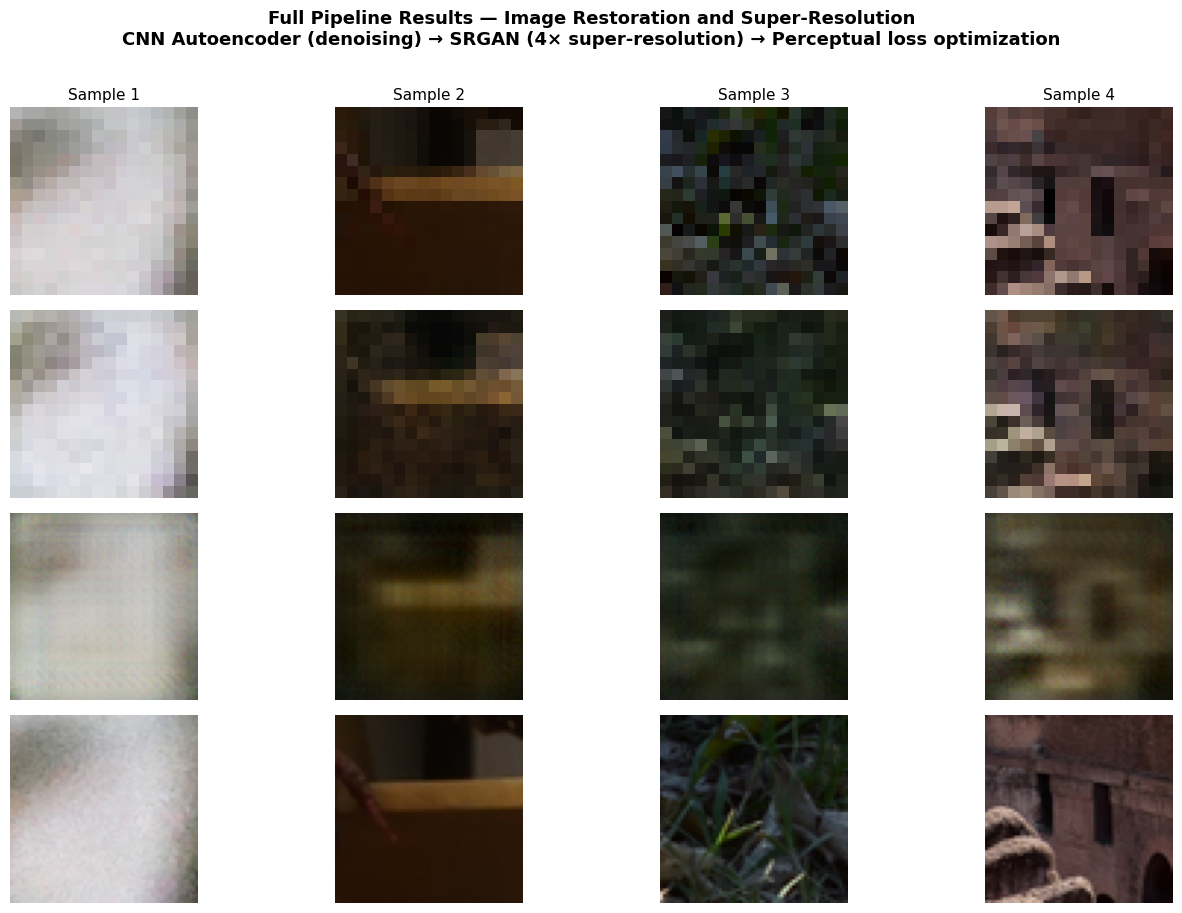


  FINAL RESULTS SUMMARY
  Sample       SRGAN PSNR   SRGAN SSIM   Bicubic PSNR  Bicubic SSIM
----------------------------------------------------------
  Sample 1         22.61dB       0.6936         33.23dB       0.8470
  Sample 2         27.59dB       0.6960         33.43dB       0.9073
  Sample 3         22.52dB       0.3762         23.39dB       0.5712
  Sample 4         20.92dB       0.5206         23.95dB       0.7212
----------------------------------------------------------
  Average          23.41dB       0.5716         28.50dB       0.7617

All results saved to Drive: /content/drive/MyDrive/SRGAN_Project/full_pipeline_results.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
G.eval()
DAE.eval()

print("Running full pipeline on 4 sample images...")

fig, axes = plt.subplots(4, 4, figsize=(14, 9))
fig.suptitle(
    'Full Pipeline Results — Image Restoration and Super-Resolution\n'
    'CNN Autoencoder (denoising) → SRGAN (4× super-resolution) → Perceptual loss optimization',
    fontsize=13, fontweight='bold', y=1.01
)

row_labels = [
    'LR input\n(degraded)',
    'After DAE\n(denoised)',
    'SRGAN output\n(super-resolved)',
    'Ground truth HR\n(reference)'
]
colors = ['#712B13', '#633806', '#3C3489', '#085041']

all_srgan_psnr   = []
all_srgan_ssim   = []
all_bicubic_psnr = []
all_bicubic_ssim = []

for i in range(4):
    lr, hr = dataset[i]
    lr_input = lr.unsqueeze(0).to(device)
    hr_np    = hr.permute(1,2,0).numpy()
    lr_np    = lr.permute(1,2,0).numpy()

    with torch.no_grad():
        lr_noisy  = add_noise(lr_input)
        lr_clean  = DAE(lr_noisy)
        sr_output = G(lr_clean).squeeze().cpu().clamp(0,1)

    clean_np = lr_clean.squeeze().cpu().permute(1,2,0).numpy().clip(0,1)
    sr_np    = sr_output.permute(1,2,0).numpy()

    sr_resized = cv2.resize(sr_np, (hr_np.shape[1], hr_np.shape[0]))
    bicubic    = cv2.resize(lr_np, (hr_np.shape[1], hr_np.shape[0]),
                            interpolation=cv2.INTER_CUBIC)

    sp = psnr(hr_np, sr_resized, data_range=1.0)
    ss = ssim(hr_np, sr_resized, data_range=1.0, channel_axis=2)
    bp = psnr(hr_np, bicubic, data_range=1.0)
    bs = ssim(hr_np, bicubic, data_range=1.0, channel_axis=2)

    all_srgan_psnr.append(sp)
    all_srgan_ssim.append(ss)
    all_bicubic_psnr.append(bp)
    all_bicubic_ssim.append(bs)

    for row, (img, label) in enumerate(zip(
            [lr_np, clean_np, sr_np, hr_np], row_labels)):
        axes[row, i].imshow(img)
        axes[row, i].axis('off')
        if i == 0:
            axes[row, i].set_ylabel(label, fontsize=10,
                                    color=colors[row], fontweight='bold',
                                    rotation=0, labelpad=130, va='center')
        if row == 0:
            axes[row, i].set_title(f'Sample {i+1}', fontsize=11)
        if row == 2:
            axes[row, i].set_xlabel(
                f'PSNR: {sp:.2f} dB  |  SSIM: {ss:.3f}',
                fontsize=9, color='#3C3489')
        if row == 3:
            axes[row, i].set_xlabel(
                f'Bicubic PSNR: {bp:.2f} dB  |  SSIM: {bs:.3f}',
                fontsize=9, color='#085041')

plt.tight_layout()
full_result_path = '/content/drive/MyDrive/SRGAN_Project/full_pipeline_results.png'
plt.savefig(full_result_path, dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "=" * 58)
print("  FINAL RESULTS SUMMARY")
print("=" * 58)
print(f"  {'Sample':<10} {'SRGAN PSNR':>12} {'SRGAN SSIM':>12} {'Bicubic PSNR':>14} {'Bicubic SSIM':>13}")
print("-" * 58)
for i in range(4):
    print(f"  {'Sample '+str(i+1):<10} "
          f"{all_srgan_psnr[i]:>11.2f}dB "
          f"{all_srgan_ssim[i]:>12.4f} "
          f"{all_bicubic_psnr[i]:>13.2f}dB "
          f"{all_bicubic_ssim[i]:>12.4f}")
print("-" * 58)
print(f"  {'Average':<10} "
      f"{sum(all_srgan_psnr)/4:>11.2f}dB "
      f"{sum(all_srgan_ssim)/4:>12.4f} "
      f"{sum(all_bicubic_psnr)/4:>13.2f}dB "
      f"{sum(all_bicubic_ssim)/4:>12.4f}")
print("=" * 58)
print(f"\nAll results saved to Drive: {full_result_path}")

from google.colab import files
files.download(full_result_path)
files.download('/content/drive/MyDrive/SRGAN_Project/dae_results.png')
files.download('/content/drive/MyDrive/SRGAN_Project/dataset_samples.png')